<a href="https://colab.research.google.com/github/dhanwariagarvit21/unified_theory_of_orderflow_vol_implementation/blob/main/first_unified_theory_implementaition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import torch
import zipfile
import torch.nn.functional as F
import gc
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import expon
from scipy.optimize import minimize
from torch._higher_order_ops.associative_scan import associative_scan


In [2]:
columns = [
    "trade_id",
    "price",
    "qty",
    "quote_qty",
    "timestamp",
    "is_buyer_maker",
    "is_best_match"
]
df = pd.read_csv('/content/BTCEUR-trades-2026-10.csv',header=None,names=columns)

In [3]:
df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="us",
    utc=True
)
df["direction"] = df["is_buyer_maker"].map({
    True: -1,
    False: 1
})
df["signed_qty"] = (
    df["direction"] * df["qty"]
)

df["signed_quote_qty"] = (
    df["direction"] * df["quote_qty"]
)
df["buy_event"] = (
    df["direction"] == 1
).astype(int)

df["sell_event"] = (
    df["direction"] == -1
).astype(int)
df = df.sort_values(
    ["timestamp", "trade_id"]
).reset_index(drop=True)

df["interarrival_ms"] = (
    df["timestamp"].diff() / 1000
)

In [4]:
print("Duplicate trade IDs:",
      df["trade_id"].duplicated().sum())

print("Missing values:")
print(df.isna().sum())

print("Buy-initiated trades:",
      df["buy_event"].sum())

print("Sell-initiated trades:",
      df["sell_event"].sum())

print("Direction balance:")
print(df["direction"].value_counts(normalize=True))

print("Total signed quantity:",
      df["signed_qty"].sum())

Duplicate trade IDs: 0
Missing values:
trade_id            0
price               0
qty                 0
quote_qty           0
timestamp           0
is_buyer_maker      0
is_best_match       0
datetime            0
direction           0
signed_qty          0
signed_quote_qty    0
buy_event           0
sell_event          0
interarrival_ms     1
dtype: int64
Buy-initiated trades: 318945
Sell-initiated trades: 366116
Direction balance:
direction
-1    0.534428
 1    0.465572
Name: proportion, dtype: float64
Total signed quantity: -240.04236999999998


In [5]:

df = df.sort_values(
    ["timestamp", "trade_id"]
).reset_index(drop=True)
df["interarrival_ms"] = (
    df["timestamp"].diff() / 1000
)
print("Total trades:", len(df))
print("Unique timestamps:", df["timestamp"].nunique())
print("Simultaneous timestamp records:",
      df["timestamp"].duplicated().sum())

print("\nInter-arrival time statistics:")
print(df["interarrival_ms"].describe())

print("\nNegative inter-arrival times:",
      (df["interarrival_ms"] < 0).sum())

Total trades: 685061
Unique timestamps: 536074
Simultaneous timestamp records: 148987

Inter-arrival time statistics:
count    685060.000000
mean       3909.726821
std       11738.298244
min           0.000000
25%           0.028000
50%           2.062000
75%        2324.894000
max      774306.592000
Name: interarrival_ms, dtype: float64

Negative inter-arrival times: 0


In [6]:
buy_events = df.loc[
    df["direction"] == 1,
    ["timestamp", "qty"]
].copy()

sell_events = df.loc[
    df["direction"] == -1,
    ["timestamp", "qty"]
].copy()

print("Buy events:", len(buy_events))
print("Sell events:", len(sell_events))

Buy events: 318945
Sell events: 366116


In [7]:
df

,trade_id,price,qty,quote_qty,timestamp,is_buyer_maker,is_best_match,datetime,direction,signed_qty,signed_quote_qty,buy_event,sell_event,interarrival_ms
0,177069239,73760.52,0.00072,53.107574,1790812801147152,False,True,2026-10-01 00:00:01.147152+00:00,1,0.00072,53.107574,1,0,NaN
1,177069240,73780.62,0.00777,573.275417,1790812802040769,False,True,2026-10-01 00:00:02.040769+00:00,1,0.00777,573.275417,1,0,893.617
2,177069241,73783.95,0.00805,593.960798,1790812802312021,False,True,2026-10-01 00:00:02.312021+00:00,1,0.00805,593.960798,1,0,271.252
3,177069242,73783.95,0.00241,177.819320,1790812802312165,False,True,2026-10-01 00:00:02.312165+00:00,1,0.00241,177.819320,1,0,0.144
4,177069243,73783.95,0.00256,188.886912,1790812802312235,False,True,2026-10-01 00:00:02.312235+00:00,1,0.00256,188.886912,1,0,0.070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
685056,177754295,68563.05,0.00819,561.531379,1793491198588817,True,True,2026-10-31 23:59:58.588817+00:00,-1,-0.00819,-561.531379,0,1,0.245
685057,177754296,68563.05,0.00150,102.844575,1793491198590094,True,True,2026-10-31 23:59:58.590094+00:00,-1,-0.00150,-102.844575,0,1,1.277
685058,177754297,68563.05,0.00150,102.844575,1793491198590459,True,True,2026-10-31 23:59:58.590459+00:00,-1,-0.00150,-102.844575,0,1,0.365
685059,177754298,68563.05,0.00014,9.598827,1793491198590568,True,True,2026-10-31 23:59:58.590568+00:00,-1,-0.00014,-9.598827,0,1,0.109


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 685061 entries, 0 to 685060
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype              
---  ------            --------------   -----              
 0   trade_id          685061 non-null  int64              
 1   price             685061 non-null  float64            
 2   qty               685061 non-null  float64            
 3   quote_qty         685061 non-null  float64            
 4   timestamp         685061 non-null  int64              
 5   is_buyer_maker    685061 non-null  bool               
 6   is_best_match     685061 non-null  bool               
 7   datetime          685061 non-null  datetime64[ns, UTC]
 8   direction         685061 non-null  int64              
 9   signed_qty        685061 non-null  float64            
 10  signed_quote_qty  685061 non-null  float64            
 11  buy_event         685061 non-null  int64              
 12  sell_event        685061 non-null  int64    

In [9]:
df.describe()

,trade_id,price,qty,quote_qty,timestamp,direction,signed_qty,signed_quote_qty,buy_event,sell_event,interarrival_ms
count,6.850610e+05,685061.000000,685061.000000,685061.000000,6.850610e+05,685061.000000,685061.000000,685061.000000,685061.000000,685061.000000,685060.000000
mean,1.774118e+08,72624.883422,0.004434,321.391156,1.792315e+15,-0.068857,-0.000350,-24.614734,0.465572,0.534428,3909.726821
std,1.977602e+05,2624.875387,0.014510,1039.081299,8.599989e+11,0.997627,0.015168,1087.371365,0.498814,0.498814,11738.298244
min,1.770692e+08,66632.000000,0.000010,0.666320,1.790813e+15,-1.000000,-3.367810,-237015.320349,0.000000,0.000000,0.000000
25%,1.772405e+08,71456.240000,0.000290,21.280629,1.791491e+15,-1.000000,-0.001370,-100.045125,0.000000,0.000000,0.028000
50%,1.774118e+08,72948.590000,0.001200,87.592206,1.792401e+15,-1.000000,-0.000100,-7.408382,0.000000,1.000000,2.062000
75%,1.775830e+08,74417.570000,0.004190,300.975557,1.793213e+15,1.000000,0.001000,72.147174,1.000000,1.000000,2324.894000
max,1.777543e+08,77527.860000,3.367810,237015.320349,1.793491e+15,1.000000,0.733040,53995.703226,1.000000,1.000000,774306.592000


In [10]:

df = df.sort_values(
    ["timestamp", "trade_id"]
).reset_index(drop=True)
df["interarrival_ms"] = (
    df["timestamp"].diff() / 1000
)
print("Chronologically sorted:",
      df["timestamp"].is_monotonic_increasing)
print("Negative intervals:",
      (df["interarrival_ms"] < 0).sum())
print("Zero intervals:",
      (df["interarrival_ms"] == 0).sum())
print("Positive intervals:",
      (df["interarrival_ms"] > 0).sum())
timestamp_groups = (
    df.groupby("timestamp")
      .size()
      .sort_values(ascending=False)
)

print("\nLargest simultaneous event groups:")
print(timestamp_groups.head(10))

print("\nSimultaneous group statistics:")
print(timestamp_groups.describe())

Chronologically sorted: True
Negative intervals: 0
Zero intervals: 148987
Positive intervals: 536073

Largest simultaneous event groups:
timestamp
1793351205514986    147
1793351215564070    142
1793390062665330     83
1793346662944548     82
1791338459292850     78
1791267836761735     77
1791184527392141     77
1791179081861241     75
1791264029944732     73
1791263897405160     68
dtype: int64

Simultaneous group statistics:
count    536074.000000
mean          1.277922
std           1.100561
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         147.000000
dtype: float64


In [11]:

largest_timestamp = timestamp_groups.index[0]
largest_group = df[
    df["timestamp"] == largest_timestamp
].copy()

print("Timestamp:", largest_timestamp)
print("Number of trades:", len(largest_group))

print("\nDirection distribution:")
print(largest_group["direction"].value_counts())

print("\nUnique prices:", largest_group["price"].nunique())

print("\nTrade ID range:")
print(
    largest_group["trade_id"].min(),
    largest_group["trade_id"].max()
)

print("\nTrade records:")
print(
    largest_group[
        ["trade_id", "price", "qty", "direction"]
    ].head(20)
)

Timestamp: 1793351205514986
Number of trades: 147

Direction distribution:
direction
1    147
Name: count, dtype: int64

Unique prices: 136

Trade ID range:
177659923 177660069

Trade records:
         trade_id     price      qty  direction
590684  177659923  67107.90  0.00224          1
590685  177659924  67108.95  0.03333          1
590686  177659925  67109.16  0.03288          1
590687  177659926  67109.18  0.02002          1
590688  177659927  67134.26  0.00642          1
590689  177659928  67134.27  0.00232          1
590690  177659929  67135.37  0.00428          1
590691  177659930  67136.78  0.02495          1
590692  177659931  67143.60  0.02495          1
590693  177659932  67144.08  0.01481          1
590694  177659933  67147.29  0.02495          1
590695  177659934  67150.91  0.00102          1
590696  177659935  67154.69  0.00121          1
590697  177659936  67160.92  0.00191          1
590698  177659937  67177.96  0.00080          1
590699  177659938  67242.48  0.00128   

In [12]:

largest_timestamp = timestamp_groups.index[0]
largest_group = df[
    df["timestamp"] == largest_timestamp
].copy()

print("Timestamp:", largest_timestamp)
print("Number of trades:", len(largest_group))

print("\nDirection distribution:")
print(largest_group["direction"].value_counts())

print("\nUnique prices:", largest_group["price"].nunique())

print("\nTrade ID range:")
print(
    largest_group["trade_id"].min(),
    largest_group["trade_id"].max()
)

print("\nTrade records:")
print(
    largest_group[
        ["trade_id", "price", "qty", "direction"]
    ].head(20)
)

Timestamp: 1793351205514986
Number of trades: 147

Direction distribution:
direction
1    147
Name: count, dtype: int64

Unique prices: 136

Trade ID range:
177659923 177660069

Trade records:
         trade_id     price      qty  direction
590684  177659923  67107.90  0.00224          1
590685  177659924  67108.95  0.03333          1
590686  177659925  67109.16  0.03288          1
590687  177659926  67109.18  0.02002          1
590688  177659927  67134.26  0.00642          1
590689  177659928  67134.27  0.00232          1
590690  177659929  67135.37  0.00428          1
590691  177659930  67136.78  0.02495          1
590692  177659931  67143.60  0.02495          1
590693  177659932  67144.08  0.01481          1
590694  177659933  67147.29  0.02495          1
590695  177659934  67150.91  0.00102          1
590696  177659935  67154.69  0.00121          1
590697  177659936  67160.92  0.00191          1
590698  177659937  67177.96  0.00080          1
590699  177659938  67242.48  0.00128   

In [13]:
batch_df = (
    df.groupby(
        ["timestamp", "direction"],
        sort=True
    )
    .agg(
        datetime=("datetime", "first"),
        trade_count=("trade_id", "count"),
        total_qty=("qty", "sum"),
        total_quote_qty=("quote_qty", "sum"),
        first_price=("price", "first"),
        last_price=("price", "last"),
        min_price=("price", "min"),
        max_price=("price", "max"),
        first_trade_id=("trade_id", "first"),
        last_trade_id=("trade_id", "last")
    )
    .reset_index()
)

batch_df["vwap"] = (
    batch_df["total_quote_qty"] /
    batch_df["total_qty"]
)

batch_df["price_range"] = (
    batch_df["max_price"] -
    batch_df["min_price"]
)

batch_df["price_displacement"] = (
    batch_df["last_price"] -
    batch_df["first_price"]
)

batch_df["directional_displacement"] = (
    batch_df["direction"] *
    batch_df["price_displacement"]
)

In [14]:
batch_df

,timestamp,direction,datetime,trade_count,total_qty,total_quote_qty,first_price,last_price,min_price,max_price,first_trade_id,last_trade_id,vwap,price_range,price_displacement,directional_displacement
0,1790812801147152,1,2026-10-01 00:00:01.147152+00:00,1,0.00072,53.107574,73760.52,73760.52,73760.52,73760.52,177069239,177069239,73760.52,0.0,0.0,0.0
1,1790812802040769,1,2026-10-01 00:00:02.040769+00:00,1,0.00777,573.275417,73780.62,73780.62,73780.62,73780.62,177069240,177069240,73780.62,0.0,0.0,0.0
2,1790812802312021,1,2026-10-01 00:00:02.312021+00:00,1,0.00805,593.960798,73783.95,73783.95,73783.95,73783.95,177069241,177069241,73783.95,0.0,0.0,0.0
3,1790812802312165,1,2026-10-01 00:00:02.312165+00:00,1,0.00241,177.819320,73783.95,73783.95,73783.95,73783.95,177069242,177069242,73783.95,0.0,0.0,0.0
4,1790812802312235,1,2026-10-01 00:00:02.312235+00:00,1,0.00256,188.886912,73783.95,73783.95,73783.95,73783.95,177069243,177069243,73783.95,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
536144,1793491198588817,-1,2026-10-31 23:59:58.588817+00:00,1,0.00819,561.531379,68563.05,68563.05,68563.05,68563.05,177754295,177754295,68563.05,0.0,0.0,-0.0
536145,1793491198590094,-1,2026-10-31 23:59:58.590094+00:00,1,0.00150,102.844575,68563.05,68563.05,68563.05,68563.05,177754296,177754296,68563.05,0.0,0.0,-0.0
536146,1793491198590459,-1,2026-10-31 23:59:58.590459+00:00,1,0.00150,102.844575,68563.05,68563.05,68563.05,68563.05,177754297,177754297,68563.05,0.0,0.0,-0.0
536147,1793491198590568,-1,2026-10-31 23:59:58.590568+00:00,1,0.00014,9.598827,68563.05,68563.05,68563.05,68563.05,177754298,177754298,68563.05,0.0,0.0,-0.0


In [15]:
batch_df['timestamp'].nunique()

536074

In [16]:
print(batch_df["trade_count"].describe(
    percentiles=[.50, .75, .90, .95, .99, .999]
))

print(
    batch_df["trade_count"].value_counts()
      .sort_index()
      .tail(20)
)

count    536149.000000
mean          1.277744
std           1.098408
min           1.000000
50%           1.000000
75%           1.000000
90%           2.000000
95%           2.000000
99%           5.000000
99.9%        14.000000
max         147.000000
Name: trade_count, dtype: float64
trade_count
44     1
45     1
46     2
47     1
50     1
55     1
56     1
58     2
61     3
64     1
66     2
68     1
73     1
74     1
75     1
77     2
82     1
83     1
142    1
147    1
Name: count, dtype: int64


In [17]:
print(
    batch_df[
        [
            "trade_count",
            "total_qty",
            "price_range",
            "directional_displacement"
        ]
    ].corr()
)

                          trade_count  total_qty  price_range  \
trade_count                  1.000000   0.500912     0.605388   
total_qty                    0.500912   1.000000     0.271647   
price_range                  0.605388   0.271647     1.000000   
directional_displacement     0.605381   0.271647     0.999999   

                          directional_displacement  
trade_count                               0.605381  
total_qty                                 0.271647  
price_range                               0.999999  
directional_displacement                  1.000000  


In [18]:
print(
    "Single-execution batches:",
    (batch_df["trade_count"] == 1).sum()
)

print(
    "Multi-execution batches:",
    (batch_df["trade_count"] > 1).sum()
)

print(
    "Executions represented in multi-execution batches:",
    batch_df.loc[
        batch_df["trade_count"] > 1,
        "trade_count"
    ].sum()
)

Single-execution batches: 443866
Multi-execution batches: 92283
Executions represented in multi-execution batches: 241195


In [19]:
print(pd.crosstab(
    df["is_buyer_maker"],
    df["direction"]
))

print("\nCorrected event counts:")
print("Buy:", df["buy_event"].sum())
print("Sell:", df["sell_event"].sum())

print("\nSigned BTC volume:", df["signed_qty"].sum())

print("\nDirectional displacement:")
print(
    batch_df.groupby("direction")[
        "directional_displacement"
    ].describe()
)

print("\nPositive displacement share:")
print(
    (batch_df["directional_displacement"] > 0).mean()
)

direction           -1       1
is_buyer_maker                
False                0  318945
True            366116       0

Corrected event counts:
Buy: 318945
Sell: 366116

Signed BTC volume: -240.04236999999998

Directional displacement:
              count      mean       std  min  25%  50%  75%     max
direction                                                          
-1         280726.0  0.519953  4.086318 -2.0  0.0 -0.0 -0.0  559.49
 1         255423.0  0.371008  5.045578  0.0  0.0  0.0  0.0  868.71

Positive displacement share:
0.1121964230092754


In [20]:

batch_df["avg_trade_qty"] = (
    batch_df["total_qty"] / batch_df["trade_count"]
)

batch_df["vwap_displacement"] = (
    batch_df["direction"] *
    (batch_df["last_price"] - batch_df["vwap"])
    / batch_df["vwap"]
)
print("Original trades:", len(df))
print("Trades represented in batches:",
      batch_df["trade_count"].sum())

print("Original BTC volume:", df["qty"].sum())
print("Aggregated BTC volume:", batch_df["total_qty"].sum())

print("Original EUR volume:", df["quote_qty"].sum())
print("Aggregated EUR volume:", batch_df["total_quote_qty"].sum())

print("Unique batch keys:",
      batch_df[["timestamp", "direction"]].drop_duplicates().shape[0])

Original trades: 685061
Trades represented in batches: 685061
Original BTC volume: 3037.8329700000004
Aggregated BTC volume: 3037.83297
Original EUR volume: 220172546.63541842
Aggregated EUR volume: 220172546.63541842
Unique batch keys: 536149


In [21]:
tmp = df.set_index("datetime").sort_index().copy()
tmp["total_events"] = 1
tmp["unsigned_qty"] = tmp["qty"]
tmp["signed_qty"] = tmp["direction"] * tmp["qty"]

flow_10s = tmp.resample("10s").agg({
    "buy_event": "sum",
    "sell_event": "sum",
    "total_events": "sum",
    "unsigned_qty": "sum",
    "signed_qty": "sum"
})

print(flow_10s.head())
print(flow_10s.describe())

                           buy_event  sell_event  total_events  unsigned_qty  \
datetime                                                                       
2026-10-01 00:00:00+00:00         13           9            22       0.08303   
2026-10-01 00:00:10+00:00          2           2             4       0.01502   
2026-10-01 00:00:20+00:00          1           0             1       0.00072   
2026-10-01 00:00:30+00:00          0           1             1       0.00072   
2026-10-01 00:00:40+00:00          1           0             1       0.00598   

                           signed_qty  
datetime                               
2026-10-01 00:00:00+00:00     0.00247  
2026-10-01 00:00:10+00:00     0.01162  
2026-10-01 00:00:20+00:00     0.00072  
2026-10-01 00:00:30+00:00    -0.00072  
2026-10-01 00:00:40+00:00     0.00598  
           buy_event     sell_event   total_events   unsigned_qty  \
count  267840.000000  267840.000000  267840.000000  267840.000000   
mean        1.190804 

In [22]:
print("Before cleaning:", len(df))

df = df.dropna(
    subset=[
        "timestamp",
        "price",
        "qty",
        "is_buyer_maker"
    ]
).copy()

df = df.sort_values(
    ["timestamp", "trade_id"]
).reset_index(drop=True)

print("After cleaning:", len(df))
print("Remaining missing values:")
print(df.isna().sum())

Before cleaning: 685061
After cleaning: 685061
Remaining missing values:
trade_id            0
price               0
qty                 0
quote_qty           0
timestamp           0
is_buyer_maker      0
is_best_match       0
datetime            0
direction           0
signed_qty          0
signed_quote_qty    0
buy_event           0
sell_event          0
interarrival_ms     1
dtype: int64


In [23]:
print("Valid trades:", len(df))

print("Missing timestamps:", df["datetime"].isna().sum())
print("Missing prices:", df["price"].isna().sum())
print("Missing quantities:", df["qty"].isna().sum())

print("Duplicate trade IDs:", df["trade_id"].duplicated().sum())

print("Chronological order:",
      df["timestamp"].is_monotonic_increasing)

print("Buyer-initiated trades:", df["buy_event"].sum())
print("Seller-initiated trades:", df["sell_event"].sum())

print("Total events:",
      df["buy_event"].sum() + df["sell_event"].sum())

Valid trades: 685061
Missing timestamps: 0
Missing prices: 0
Missing quantities: 0
Duplicate trade IDs: 0
Chronological order: True
Buyer-initiated trades: 318945
Seller-initiated trades: 366116
Total events: 685061


In [24]:
tmp = df.set_index("datetime").sort_index().copy()

tmp["total_events"] = 1
tmp["unsigned_qty"] = tmp["qty"]
tmp["signed_qty"] = tmp["direction"] * tmp["qty"]

flow_10s = tmp.resample("10s").agg({
    "buy_event": "sum",
    "sell_event": "sum",
    "total_events": "sum",
    "unsigned_qty": "sum",
    "signed_qty": "sum"
})

lags = [1, 2, 3, 6, 12, 30, 60]

for column in [
    "buy_event",
    "sell_event",
    "total_events",
    "unsigned_qty",
    "signed_qty"
]:
    print(f"\n{column}")

    for lag in lags:
        print(
            f"Lag {lag:>2}: "
            f"{flow_10s[column].autocorr(lag=lag):.5f}"
        )


buy_event
Lag  1: 0.24982
Lag  2: 0.15446
Lag  3: 0.13901
Lag  6: 0.10137
Lag 12: 0.09189
Lag 30: 0.06321
Lag 60: 0.05381

sell_event
Lag  1: 0.28848
Lag  2: 0.20228
Lag  3: 0.18322
Lag  6: 0.13571
Lag 12: 0.12484
Lag 30: 0.09156
Lag 60: 0.07558

total_events
Lag  1: 0.34358
Lag  2: 0.22748
Lag  3: 0.21365
Lag  6: 0.15808
Lag 12: 0.13774
Lag 30: 0.10529
Lag 60: 0.08958

unsigned_qty
Lag  1: 0.19215
Lag  2: 0.09267
Lag  3: 0.08593
Lag  6: 0.04546
Lag 12: 0.03170
Lag 30: 0.03477
Lag 60: 0.02524

signed_qty
Lag  1: 0.05761
Lag  2: 0.01394
Lag  3: -0.01138
Lag  6: 0.00940
Lag 12: 0.00549
Lag 30: 0.00102
Lag 60: 0.00114


In [25]:

hourly_means = flow_10s.groupby(
    flow_10s.index.hour
).transform("mean")
seasonality_adjusted = flow_10s[
    ["buy_event", "sell_event", "total_events",
     "unsigned_qty", "signed_qty"]
] - hourly_means[
    ["buy_event", "sell_event", "total_events",
     "unsigned_qty", "signed_qty"]
]

lags = [1, 2, 3, 6, 12, 30, 60]

for column in seasonality_adjusted.columns:
    print(f"\n{column}")

    for lag in lags:
        correlation = seasonality_adjusted[column].autocorr(lag=lag)
        print(f"Lag {lag:>2}: {correlation:.5f}")


buy_event
Lag  1: 0.24600
Lag  2: 0.15015
Lag  3: 0.13462
Lag  6: 0.09680
Lag 12: 0.08727
Lag 30: 0.05845
Lag 60: 0.04885

sell_event
Lag  1: 0.28383
Lag  2: 0.19706
Lag  3: 0.17787
Lag  6: 0.13005
Lag 12: 0.11908
Lag 30: 0.08553
Lag 60: 0.06942

total_events
Lag  1: 0.33825
Lag  2: 0.22120
Lag  3: 0.20725
Lag  6: 0.15124
Lag 12: 0.13072
Lag 30: 0.09797
Lag 60: 0.08200

unsigned_qty
Lag  1: 0.19119
Lag  2: 0.09159
Lag  3: 0.08485
Lag  6: 0.04432
Lag 12: 0.03055
Lag 30: 0.03362
Lag 60: 0.02405

signed_qty
Lag  1: 0.05748
Lag  2: 0.01380
Lag  3: -0.01153
Lag  6: 0.00926
Lag 12: 0.00535
Lag 30: 0.00089
Lag 60: 0.00102


In [26]:
buy = flow_10s["buy_event"]
sell = flow_10s["sell_event"]

lags = [0, 1, 2, 3, 6, 12, 30, 60]

print("Buy activity preceding sell activity:")

for lag in lags:
    corr = sell.corr(buy.shift(lag))
    print(f"Lag {lag:>2}: {corr:.5f}")


print("\nSell activity preceding buy activity:")

for lag in lags:
    corr = buy.corr(sell.shift(lag))
    print(f"Lag {lag:>2}: {corr:.5f}")

Buy activity preceding sell activity:
Lag  0: 0.38456
Lag  1: 0.21838
Lag  2: 0.14428
Lag  3: 0.14872
Lag  6: 0.10313
Lag 12: 0.08311
Lag 30: 0.06563
Lag 60: 0.05872

Sell activity preceding buy activity:
Lag  0: 0.38456
Lag  1: 0.19732
Lag  2: 0.13195
Lag  3: 0.12349
Lag  6: 0.09973
Lag 12: 0.08366
Lag 30: 0.07298
Lag 60: 0.06135


In [27]:

bin_sizes = ["1s", "5s", "10s", "30s", "60s"]
horizons = [10, 30, 60, 300, 600]

results = []

for bin_size in bin_sizes:

    sampled = (
        df.set_index("datetime")
          .resample(bin_size)
          .agg(
              buy_event=("buy_event", "sum"),
              sell_event=("sell_event", "sum"),
              total_events=("trade_id", "count")
          )
    )

    seconds = pd.Timedelta(bin_size).total_seconds()

    for variable in ["buy_event", "sell_event", "total_events"]:

        row = {
            "bin_size": bin_size,
            "variable": variable
        }

        for horizon in horizons:

            if horizon < seconds:
                row[f"{horizon}s"] = None
                continue

            lag = int(horizon / seconds)

            row[f"{horizon}s"] = sampled[variable].autocorr(
                lag=lag
            )

        results.append(row)

autocorr_comparison = pd.DataFrame(results)

print(autocorr_comparison.round(4).to_string(index=False))

bin_size     variable    10s    30s    60s   300s   600s
      1s    buy_event 0.0516 0.0277 0.0195 0.0122 0.0135
      1s   sell_event 0.0460 0.0335 0.0324 0.0198 0.0139
      1s total_events 0.0728 0.0465 0.0363 0.0245 0.0215
      5s    buy_event 0.1305 0.0882 0.0571 0.0383 0.0344
      5s   sell_event 0.1461 0.1160 0.0835 0.0588 0.0451
      5s total_events 0.1911 0.1428 0.0993 0.0706 0.0580
     10s    buy_event 0.2498 0.1390 0.1014 0.0632 0.0538
     10s   sell_event 0.2885 0.1832 0.1357 0.0916 0.0756
     10s total_events 0.3436 0.2136 0.1581 0.1053 0.0896
     30s    buy_event    NaN 0.3027 0.2283 0.1436 0.1094
     30s   sell_event    NaN 0.3588 0.2593 0.1821 0.1413
     30s total_events    NaN 0.3964 0.2961 0.2004 0.1601
     60s    buy_event    NaN    NaN 0.3579 0.2064 0.1625
     60s   sell_event    NaN    NaN 0.4125 0.2657 0.2095
     60s total_events    NaN    NaN 0.4450 0.2806 0.2255


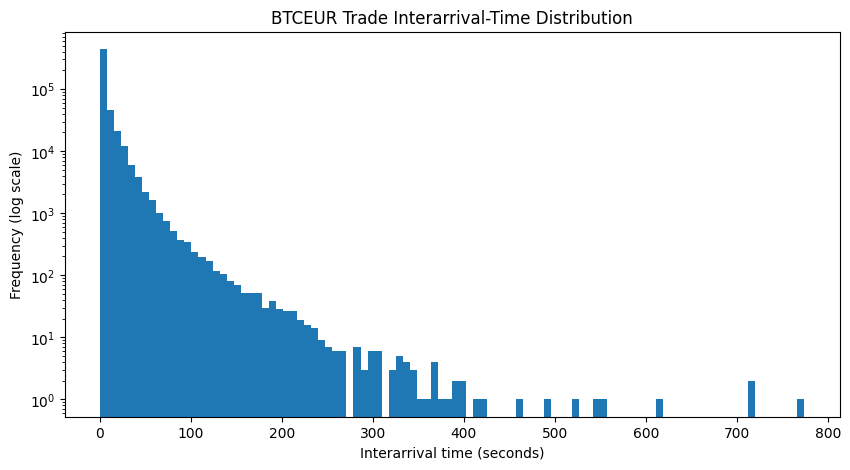

In [28]:
interarrivals = df.copy()

interarrivals["interarrival_seconds"] = (
    interarrivals["timestamp"].diff() / 1_000_000
)

valid = interarrivals[
    interarrivals["interarrival_seconds"] > 0
]

plt.figure(figsize=(10, 5))

plt.hist(
    valid["interarrival_seconds"],
    bins=100,
    log=True
)

plt.xlabel("Interarrival time (seconds)")
plt.ylabel("Frequency (log scale)")
plt.title("BTCEUR Trade Interarrival-Time Distribution")

plt.show()

Positive interarrival observations: 536073
count    536073.000000
mean          4.996330
std          13.063423
min           0.000001
1%            0.000003
5%            0.000037
25%           0.000753
50%           0.075104
75%           4.346294
95%          25.000028
99%          56.786596
max         774.306592
Name: interarrival_seconds, dtype: float64


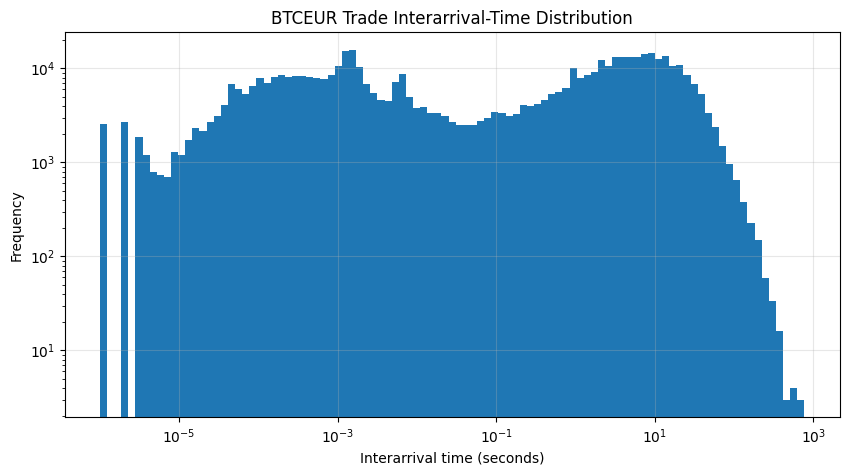

In [29]:
interarrivals = df.copy()

interarrivals["interarrival_seconds"] = (
    interarrivals["timestamp"].diff() / 1_000_000
)
positive_intervals = interarrivals.loc[
    interarrivals["interarrival_seconds"] > 0,
    "interarrival_seconds"
]

print("Positive interarrival observations:", len(positive_intervals))

print(positive_intervals.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
))

plt.figure(figsize=(10, 5))

plt.hist(
    positive_intervals,
    bins=np.logspace(
        np.log10(positive_intervals.min()),
        np.log10(positive_intervals.max()),
        100
    )
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Interarrival time (seconds)")
plt.ylabel("Frequency")
plt.title("BTCEUR Trade Interarrival-Time Distribution")
plt.grid(True, alpha=0.3)

plt.show()

Mean interarrival: 4.996329708909048
Estimated arrival rate: 0.20014691949109792
Events per second: 0.20014691949109792


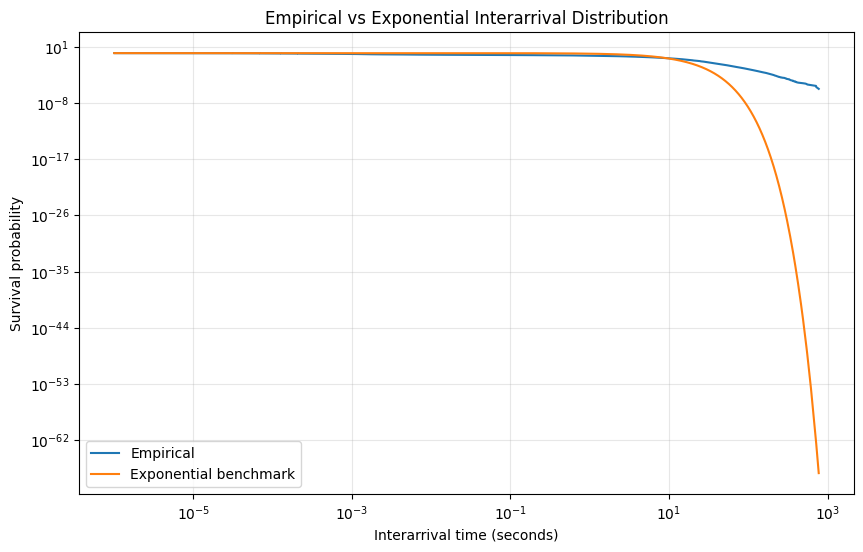

In [30]:
tau = positive_intervals.to_numpy()
mean_tau = tau.mean()
lambda_hat = 1 / mean_tau

print("Mean interarrival:", mean_tau)
print("Estimated arrival rate:", lambda_hat)
print("Events per second:", lambda_hat)


sorted_tau = np.sort(tau)
n = len(sorted_tau)
empirical_survival = (
    n - np.arange(n)
) / n

theoretical_survival = np.exp(
    -lambda_hat * sorted_tau
)

plt.figure(figsize=(10, 6))

plt.plot(
    sorted_tau,
    empirical_survival,
    label="Empirical"
)

plt.plot(
    sorted_tau,
    theoretical_survival,
    label="Exponential benchmark"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Interarrival time (seconds)")
plt.ylabel("Survival probability")

plt.title("Empirical vs Exponential Interarrival Distribution")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [31]:
print("Number of positive intervals:", len(positive_intervals))
print("Mean:", positive_intervals.mean())
print("Median:", positive_intervals.median())
print("Minimum:", positive_intervals.min())
print("Maximum:", positive_intervals.max())

print("Number of valid executions:", len(df))
print("Number of unique timestamps:", df["timestamp"].nunique())

Number of positive intervals: 536073
Mean: 4.996329708909048
Median: 0.075104
Minimum: 1e-06
Maximum: 774.306592
Number of valid executions: 685061
Number of unique timestamps: 536074


In [32]:
# Extract unique timestamps for each aggressor direction
buy_times = np.sort(
    df.loc[df["direction"] == 1, "timestamp"].unique()
)

sell_times = np.sort(
    df.loc[df["direction"] == -1, "timestamp"].unique()
)

# Calculate positive interarrival times in seconds
buy_intervals = np.diff(buy_times) / 1_000_000
sell_intervals = np.diff(sell_times) / 1_000_000

print("Buy mean:", buy_intervals.mean())
print("Buy median:", np.median(buy_intervals))

print("Sell mean:", sell_intervals.mean())
print("Sell median:", np.median(sell_intervals))

Buy mean: 10.486149673567665
Buy median: 0.026408
Sell mean: 9.540985788219789
Sell median: 0.419133


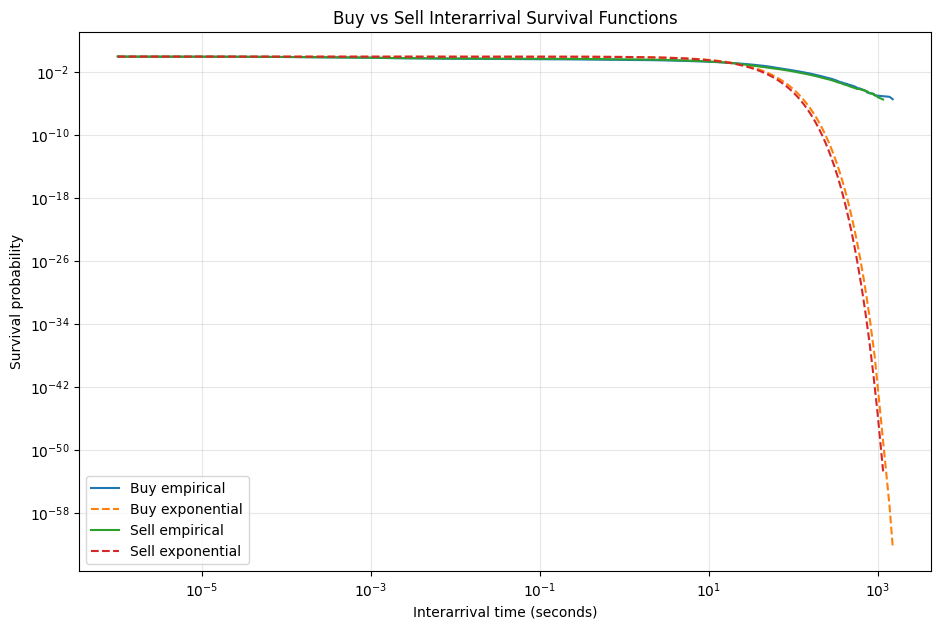

In [33]:
def plot_survival_comparison(intervals, label):
    tau = np.sort(intervals)
    n = len(tau)

    mean_tau = tau.mean()
    lambda_hat = 1 / mean_tau

    empirical_survival = (
        n - np.arange(n)
    ) / n

    theoretical_survival = np.exp(
        -lambda_hat * tau
    )

    plt.plot(
        tau,
        empirical_survival,
        label=f"{label} empirical"
    )

    plt.plot(
        tau,
        theoretical_survival,
        linestyle="--",
        label=f"{label} exponential"
    )


plt.figure(figsize=(11, 7))

plot_survival_comparison(
    buy_intervals,
    "Buy"
)

plot_survival_comparison(
    sell_intervals,
    "Sell"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Interarrival time (seconds)")
plt.ylabel("Survival probability")
plt.title("Buy vs Sell Interarrival Survival Functions")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [34]:

check_times = [
    0.001,
    0.01,
    0.0264,
    0.1,
    0.4191,
    1,
    5,
    10,
    30,
    60,
    100
]

print(f"{'Time':>10} {'Buy survival':>18} {'Sell survival':>18}")

for t in check_times:
    buy_surv = np.mean(buy_intervals > t)
    sell_surv = np.mean(sell_intervals > t)

    print(
        f"{t:10.4f} "
        f"{buy_surv:18.6f} "
        f"{sell_surv:18.6f}"
    )

      Time       Buy survival      Sell survival
    0.0010           0.725184           0.732838
    0.0100           0.533133           0.584305
    0.0264           0.500004           0.560499
    0.1000           0.467740           0.535403
    0.4191           0.428041           0.500005
    1.0000           0.395569           0.465288
    5.0000           0.288436           0.329361
   10.0000           0.224025           0.238767
   30.0000           0.104932           0.083886
   60.0000           0.042150           0.030824
  100.0000           0.017500           0.012899


In [35]:
def interval_summary(x):
    return {
        "count": len(x),
        "mean": np.mean(x),
        "median": np.median(x),
        "std": np.std(x),
        "p75": np.percentile(x, 75),
        "p90": np.percentile(x, 90),
        "p95": np.percentile(x, 95),
        "p99": np.percentile(x, 99),
        "p999": np.percentile(x, 99.9),
        "max": np.max(x)
    }

summary = pd.DataFrame({
    "Buy": interval_summary(buy_intervals),
    "Sell": interval_summary(sell_intervals)
}).T

print(summary)

         count       mean    median        std       p75        p90  \
Buy   255422.0  10.486150  0.026408  29.026172  7.682462  31.356420   
Sell  280725.0   9.540986  0.419133  24.958704  9.291810  25.910121   

            p95         p99        p999          max  
Buy   54.905056  133.198850  317.171192  1503.001164  
Sell  42.390386  113.185106  285.741003  1157.527936  


In [36]:
thresholds = [10, 30, 60, 100, 300, 600]

for t in thresholds:
    buy_fraction = np.mean(buy_intervals > t)
    sell_fraction = np.mean(sell_intervals > t)

    print(
        f"{t:>4}s | "
        f"Buy: {buy_fraction:.4%} | "
        f"Sell: {sell_fraction:.4%}"
    )

  10s | Buy: 22.4025% | Sell: 23.8767%
  30s | Buy: 10.4932% | Sell: 8.3886%
  60s | Buy: 4.2150% | Sell: 3.0824%
 100s | Buy: 1.7500% | Sell: 1.2899%
 300s | Buy: 0.1245% | Sell: 0.0841%
 600s | Buy: 0.0090% | Sell: 0.0075%


In [37]:
buy_times = np.sort(
    df.loc[df["direction"] == 1, "timestamp"].unique()
)

sell_times = np.sort(
    df.loc[df["direction"] == -1, "timestamp"].unique()
)

buy_gaps = np.diff(buy_times) / 1_000_000
sell_gaps = np.diff(sell_times) / 1_000_000

buy_idx = np.argsort(buy_gaps)[-10:][::-1]
sell_idx = np.argsort(sell_gaps)[-10:][::-1]

print("Largest buy intervals:")
for i in buy_idx:
    print(
        pd.to_datetime(buy_times[i+1], unit="us", utc=True),
        buy_gaps[i]
    )

print("\nLargest sell intervals:")
for i in sell_idx:
    print(
        pd.to_datetime(sell_times[i+1], unit="us", utc=True),
        sell_gaps[i]
    )

Largest buy intervals:
2026-10-04 05:01:05.986077+00:00 1503.001164
2026-10-04 03:21:15.470050+00:00 1378.276819
2026-10-04 04:35:25.793615+00:00 922.487079
2026-10-03 01:58:58.625438+00:00 912.245501
2026-10-10 02:40:20.906432+00:00 890.077012
2026-10-11 05:55:51.279378+00:00 815.741886
2026-10-09 23:40:07.579259+00:00 748.218595
2026-10-25 01:55:58.480454+00:00 743.683335
2026-10-04 01:49:43.772221+00:00 743.625838
2026-10-10 02:22:22.673396+00:00 730.981021

Largest sell intervals:
2026-10-04 01:57:01.653493+00:00 1157.527936
2026-10-11 06:29:54.932050+00:00 995.643317
2026-10-11 02:44:38.642617+00:00 969.908669
2026-10-25 02:00:31.519766+00:00 890.5356
2026-10-04 05:02:51.627926+00:00 879.948441
2026-10-11 03:01:53.844837+00:00 801.794821
2026-10-04 02:23:40.946570+00:00 796.681569
2026-10-11 04:31:38.026207+00:00 773.513558
2026-10-17 05:04:03.504188+00:00 768.843488
2026-10-11 04:54:50.181216+00:00 761.642886


In [38]:
buy_times = np.sort(
    df.loc[df["direction"] == 1, "timestamp"].unique()
)
sell_times = np.sort(
    df.loc[df["direction"] == -1, "timestamp"].unique()
)
all_times = np.sort(df["timestamp"].unique())

def inspect_largest_gaps(times, direction_name, top_n=10):

    gaps = np.diff(times) / 1_000_000

    largest_indices = np.argsort(gaps)[-top_n:][::-1]

    records = []

    for i in largest_indices:

        start = times[i]
        end = times[i + 1]
        between = df[
            (df["timestamp"] > start) &
            (df["timestamp"] < end)
        ]

        records.append({
            "direction": direction_name,
            "start": pd.to_datetime(
                start, unit="us", utc=True
            ),
            "end": pd.to_datetime(
                end, unit="us", utc=True
            ),
            "gap_seconds": gaps[i],
            "total_trades_between": len(between),
            "buy_trades_between": (
                between["direction"] == 1
            ).sum(),
            "sell_trades_between": (
                between["direction"] == -1
            ).sum(),
            "unique_market_timestamps": (
                between["timestamp"].nunique()
            )
        })

    return pd.DataFrame(records)


buy_gap_details = inspect_largest_gaps(
    buy_times, "Buy"
)

sell_gap_details = inspect_largest_gaps(
    sell_times, "Sell"
)

print("BUY GAPS")
display(buy_gap_details)

print("SELL GAPS")
display(sell_gap_details)

BUY GAPS


,direction,start,end,gap_seconds,total_trades_between,buy_trades_between,sell_trades_between,unique_market_timestamps
0,Buy,2026-10-04 04:36:02.984913+00:00,2026-10-04 05:01:05.986077+00:00,1503.001164,2,0,2,2
1,Buy,2026-10-04 02:58:17.193231+00:00,2026-10-04 03:21:15.470050+00:00,1378.276819,16,0,16,12
2,Buy,2026-10-04 04:20:03.306536+00:00,2026-10-04 04:35:25.793615+00:00,922.487079,2,0,2,2
3,Buy,2026-10-03 01:43:46.379937+00:00,2026-10-03 01:58:58.625438+00:00,912.245501,4,0,4,3
4,Buy,2026-10-10 02:25:30.829420+00:00,2026-10-10 02:40:20.906432+00:00,890.077012,8,0,8,6
5,Buy,2026-10-11 05:42:15.537492+00:00,2026-10-11 05:55:51.279378+00:00,815.741886,9,0,9,8
6,Buy,2026-10-09 23:27:39.360664+00:00,2026-10-09 23:40:07.579259+00:00,748.218595,6,0,6,6
7,Buy,2026-10-25 01:43:34.797119+00:00,2026-10-25 01:55:58.480454+00:00,743.683335,2,0,2,2
8,Buy,2026-10-04 01:37:20.146383+00:00,2026-10-04 01:49:43.772221+00:00,743.625838,11,0,11,7
9,Buy,2026-10-10 02:10:11.692375+00:00,2026-10-10 02:22:22.673396+00:00,730.981021,8,0,8,8


SELL GAPS


,direction,start,end,gap_seconds,total_trades_between,buy_trades_between,sell_trades_between,unique_market_timestamps
0,Sell,2026-10-04 01:37:44.125557+00:00,2026-10-04 01:57:01.653493+00:00,1157.527936,5,5,0,3
1,Sell,2026-10-11 06:13:19.288733+00:00,2026-10-11 06:29:54.932050+00:00,995.643317,15,15,0,10
2,Sell,2026-10-11 02:28:28.733948+00:00,2026-10-11 02:44:38.642617+00:00,969.908669,16,16,0,13
3,Sell,2026-10-25 01:45:40.984166+00:00,2026-10-25 02:00:31.519766+00:00,890.535600,11,11,0,10
4,Sell,2026-10-04 04:48:11.679485+00:00,2026-10-04 05:02:51.627926+00:00,879.948441,3,3,0,3
5,Sell,2026-10-11 02:48:32.050016+00:00,2026-10-11 03:01:53.844837+00:00,801.794821,7,7,0,7
6,Sell,2026-10-04 02:10:24.265001+00:00,2026-10-04 02:23:40.946570+00:00,796.681569,9,9,0,8
7,Sell,2026-10-11 04:18:44.512649+00:00,2026-10-11 04:31:38.026207+00:00,773.513558,46,46,0,45
8,Sell,2026-10-17 04:51:14.660700+00:00,2026-10-17 05:04:03.504188+00:00,768.843488,18,18,0,17
9,Sell,2026-10-11 04:42:08.538330+00:00,2026-10-11 04:54:50.181216+00:00,761.642886,13,13,0,5


In [39]:
def directional_gap_overlap(source_times, opposite_direction):
    gaps = np.diff(source_times)

    results = []

    opposite_times = np.sort(
        df.loc[
            df["direction"] == opposite_direction,
            "timestamp"
        ].unique()
    )

    for i in range(len(gaps)):
        start = source_times[i]
        end = source_times[i + 1]

        left = np.searchsorted(opposite_times, start, side="right")
        right = np.searchsorted(opposite_times, end, side="left")

        results.append(right - left)

    return np.array(results)


buy_gap_opposite = directional_gap_overlap(
    buy_times, -1
)

sell_gap_opposite = directional_gap_overlap(
    sell_times, 1
)

print("Buy gaps containing sell events:",
      np.mean(buy_gap_opposite > 0))

print("Sell gaps containing buy events:",
      np.mean(sell_gap_opposite > 0))

print("Mean sell events during buy gaps:",
      buy_gap_opposite.mean())

print("Mean buy events during sell gaps:",
      sell_gap_opposite.mean())

Buy gaps containing sell events: 0.24658408437800972
Sell gaps containing buy events: 0.22427642710838008
Mean sell events during buy gaps: 1.098703322344982
Mean buy events during sell gaps: 0.9095841125656782


In [40]:
def build_gap_dataframe(source_times, opposite_times):

    source_times = np.sort(source_times)
    opposite_times = np.sort(opposite_times)

    records = []

    for i in range(len(source_times) - 1):

        start = source_times[i]
        end = source_times[i + 1]

        duration = (end - start) / 1_000_000

        left = np.searchsorted(
            opposite_times, start, side="right"
        )

        right = np.searchsorted(
            opposite_times, end, side="left"
        )

        opposite_count = right - left

        records.append({
            "duration": duration,
            "opposite_count": opposite_count,
            "has_opposite": opposite_count > 0
        })

    return pd.DataFrame(records)


buy_gap_df = build_gap_dataframe(
    buy_times, sell_times
)

sell_gap_df = build_gap_dataframe(
    sell_times, buy_times
)

bins = [0, 1, 5, 10, 30, 60, 300, np.inf]

labels = [
    "0-1s", "1-5s", "5-10s",
    "10-30s", "30-60s", "60-300s", "300s+"
]


def summarize_gaps(gap_df):

    gap_df = gap_df.copy()

    gap_df["duration_bucket"] = pd.cut(
        gap_df["duration"],
        bins=bins,
        labels=labels
    )

    return gap_df.groupby(
        "duration_bucket",
        observed=False
    ).agg(
        gap_count=("duration", "size"),
        mean_duration=("duration", "mean"),
        probability_opposite=(
            "has_opposite", "mean"
        ),
        mean_opposite_events=(
            "opposite_count", "mean"
        )
    )


print("BUY GAPS")
display(summarize_gaps(buy_gap_df))

print("SELL GAPS")
display(summarize_gaps(sell_gap_df))

BUY GAPS


,gap_count,mean_duration,probability_opposite,mean_opposite_events
duration_bucket,,,,
0-1s,154385,0.056608,0.021628,0.085688
1-5s,27364,2.688297,0.334673,1.196353
5-10s,16452,7.301149,0.514709,1.818138
10-30s,30419,18.258321,0.653638,2.553437
30-60s,16036,42.673606,0.782864,3.597094
60-300s,10448,105.977863,0.887251,6.245502
300s+,318,405.667406,0.977987,13.037736


SELL GAPS


,gap_count,mean_duration,probability_opposite,mean_opposite_events
duration_bucket,,,,
0-1s,150107,0.066895,0.022391,0.095192
1-5s,38158,2.747352,0.258006,0.965459
5-10s,25432,7.329361,0.379994,1.480340
10-30s,43479,17.984700,0.508337,1.863244
30-60s,14896,40.662256,0.699919,2.880840
60-300s,8417,106.058711,0.872045,4.838897
300s+,236,410.000614,0.940678,8.101695


In [41]:
def summarize_opposite_activity(gap_df):
    gap_df = gap_df.copy()
    bins = [0, 1, 5, 10, 30, 60, 300, np.inf]
    labels = [
        "0-1s",
        "1-5s",
        "5-10s",
        "10-30s",
        "30-60s",
        "60-300s",
        "300s+"
    ]
    gap_df["duration_bucket"] = pd.cut(
        gap_df["duration"],
        bins=bins,
        labels=labels
    )

    gap_df["opposite_rate"] = (
        gap_df["opposite_count"] / gap_df["duration"]
    )

    return gap_df.groupby(
        "duration_bucket",
        observed=False
    ).agg(
        gap_count=("duration", "size"),
        probability_opposite=("has_opposite", "mean"),
        mean_opposite_events=("opposite_count", "mean"),
        mean_opposite_rate=("opposite_rate", "mean"),
        median_opposite_rate=("opposite_rate", "median")
    )


print("BUY GAPS")
display(summarize_opposite_activity(buy_gap_df))

print("SELL GAPS")
display(summarize_opposite_activity(sell_gap_df))

BUY GAPS


,gap_count,probability_opposite,mean_opposite_events,mean_opposite_rate,median_opposite_rate
duration_bucket,,,,,
0-1s,154385,0.021628,0.085688,9.749816,0.000000
1-5s,27364,0.334673,1.196353,0.487351,0.000000
5-10s,16452,0.514709,1.818138,0.256653,0.104019
10-30s,30419,0.653638,2.553437,0.148771,0.067429
30-60s,16036,0.782864,3.597094,0.086465,0.050660
60-300s,10448,0.887251,6.245502,0.062913,0.042888
300s+,318,0.977987,13.037736,0.033307,0.025288


SELL GAPS


,gap_count,probability_opposite,mean_opposite_events,mean_opposite_rate,median_opposite_rate
duration_bucket,,,,,
0-1s,150107,0.022391,0.095192,9.022267,0.000000
1-5s,38158,0.258006,0.965459,0.395601,0.000000
5-10s,25432,0.379994,1.480340,0.207887,0.000000
10-30s,43479,0.508337,1.863244,0.110302,0.034584
30-60s,14896,0.699919,2.880840,0.071099,0.033175
60-300s,8417,0.872045,4.838897,0.049812,0.031402
300s+,236,0.940678,8.101695,0.020872,0.014222


In [42]:
buy_times = np.sort(
    df.loc[df["direction"] == 1, "timestamp"].unique()
)

sell_times = np.sort(
    df.loc[df["direction"] == -1, "timestamp"].unique()
)

In [43]:
print("Buy events:", len(buy_times))
print("Sell events:", len(sell_times))

print("Buy sorted:", np.all(np.diff(buy_times) > 0))
print("Sell sorted:", np.all(np.diff(sell_times) > 0))

print("Buy range:", buy_times[0], buy_times[-1])
print("Sell range:", sell_times[0], sell_times[-1])

Buy events: 255423
Sell events: 280726
Buy sorted: True
Sell sorted: True
Buy range: 1790812801147152 1793491194469074
Sell range: 1790812805367798 1793491198603196


In [44]:

t0 = min(buy_times[0], sell_times[0])

buy_t = (buy_times - t0) / 1_000_000
sell_t = (sell_times - t0) / 1_000_000

T = max(buy_t[-1], sell_t[-1])
buy_t = torch.tensor(buy_t, dtype=torch.float64)
sell_t = torch.tensor(sell_t, dtype=torch.float64)
print("Observation window:", T, "seconds")
print("Buy events:", len(buy_t))
print("Sell events:", len(sell_t))

Observation window: 2678397.456044 seconds
Buy events: 255423
Sell events: 280726


In [45]:
def hawkes_nll_gpu(params, times, T):

    mu, eta, beta = params
    alpha = eta * beta
    dt = times[1:] - times[:-1]
    a = torch.exp(-beta * dt)
    def combine(left, right):
        a1, b1 = left
        a2, b2 = right

        return (
            a2 * a1,
            a2 * b1 + b2
        )
    scan_a, scan_b = associative_scan(
        combine,
        (a, a),
        dim=0
    )
    excitation = torch.cat([
        torch.zeros(1, device=times.device),
        scan_b
    ])

    intensity = mu + alpha * excitation

    compensator = (
        mu * T
        + eta * torch.sum(
            1 - torch.exp(-beta * (T - times))
        )
    )

    log_likelihood = (
        torch.sum(torch.log(intensity))
        - compensator
    )

    return -log_likelihood


def fit_hawkes(times, T):
    initial_rate = len(times) / T

    initial_params = [
        initial_rate * 0.5,
        0.5,
        1.0
    ]

    result = minimize(
        hawkes_nll_gpu,
        initial_params,
        args=(times, T),
        method="L-BFGS-B",
        bounds=[
            (1e-8, 10),
            (1e-6, 0.999),
            (1e-7, 10)
        ],
        options={
            "maxiter": 1000,
            "ftol": 1e-10
        }
    )

    mu, branching_ratio, beta = result.x
    alpha = branching_ratio * beta

    return {
        "mu": mu,
        "alpha": alpha,
        "beta": beta,
        "branching_ratio": branching_ratio,
        "log_likelihood": -result.fun,
        "success": result.success,
        "message": result.message
    }


In [46]:

buy_model = fit_hawkes(buy_t, T)
sell_model = fit_hawkes(sell_t, T)

print("BUY HAWKES MODEL")
for key, value in buy_model.items():
    print(f"{key}: {value}")

print("\nSELL HAWKES MODEL")
for key, value in sell_model.items():
    print(f"{key}: {value}")


BUY HAWKES MODEL
mu: 0.04030620073196671
alpha: 5.773440912199316
beta: 10.0
branching_ratio: 0.5773440912199316
log_likelihood: -217997.89383418232
success: True
message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH

SELL HAWKES MODEL
mu: 0.05225696635799572
alpha: 5.014440249134145
beta: 10.0
branching_ratio: 0.5014440249134144
log_likelihood: -332385.0026020283
success: True
message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH


In [47]:

def fit_hawkes_multistart(times, T):

    initial_rate = len(times) / T

    beta_starts = [0.1, 1, 10, 50, 100, 500]
    branching_starts = [0.2, 0.5, 0.8]

    best_result = None

    for beta0 in beta_starts:
        for eta0 in branching_starts:

            initial_params = [
                initial_rate * (1 - eta0),
                eta0,
                beta0
            ]

            result = minimize(
                hawkes_nll_gpu,
                initial_params,
                args=(times, T),
                method="L-BFGS-B",
                bounds=[
                    (1e-8, 10),
                    (1e-6, 0.999),
                    (1e-7, 1000)
                ],
                options={
                    "maxiter": 2000,
                    "ftol": 1e-12,
                    "gtol": 1e-7,
                    "maxls": 50
                }
            )

            if (
                result.success
                and (
                    best_result is None
                    or result.fun < best_result.fun
                )
            ):
                best_result = result

    if best_result is None:
        raise RuntimeError("No optimization run converged.")

    mu, eta, beta = best_result.x
    alpha = eta * beta

    return {
        "mu": mu,
        "alpha": alpha,
        "beta": beta,
        "branching_ratio": eta,
        "decay_timescale_seconds": 1 / beta,
        "log_likelihood": -best_result.fun,
        "success": best_result.success,
        "beta_at_upper_bound": beta > 999,
        "message": best_result.message
    }


buy_model = fit_hawkes_multistart(buy_t, T)
sell_model = fit_hawkes_multistart(sell_t, T)

print("BUY MODEL")
print(buy_model)

print("\nSELL MODEL")
print(sell_model)


BUY MODEL
{'mu': np.float64(0.04807099276637725), 'alpha': np.float64(174.1559171017699), 'beta': np.float64(351.176370088652), 'branching_ratio': np.float64(0.49592151390426825), 'decay_timescale_seconds': np.float64(0.002847572004197085), 'log_likelihood': -10755.749840144534, 'success': True, 'beta_at_upper_bound': np.False_, 'message': 'CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH'}

SELL MODEL
{'mu': np.float64(0.05991461704408459), 'alpha': np.float64(216.89304649596227), 'beta': np.float64(506.3359794241932), 'branching_ratio': np.float64(0.42835795856856484), 'decay_timescale_seconds': np.float64(0.0019749732206216174), 'log_likelihood': -96651.63133929961, 'success': True, 'beta_at_upper_bound': np.False_, 'message': 'CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH'}


In [48]:
def hawkes_nll(params, times, T):
    mu, branching_ratio, beta = params
    alpha = branching_ratio * beta

    if mu <= 0 or beta <= 0:
        return np.inf

    if not 0 < branching_ratio < 1:
        return np.inf

    n = len(times)
    excitation = np.zeros(n)

    for i in range(1, n):
        dt = times[i] - times[i - 1]

        excitation[i] = (
            np.exp(-beta * dt)
            * (1 + excitation[i - 1])
        )
    intensity = mu + alpha * excitation

    if np.any(intensity <= 0):
        return np.inf
    compensator = (
        mu * T
        + (alpha / beta)
        * np.sum(1 - np.exp(-beta * (T - times)))
    )

    log_likelihood = (
        np.sum(np.log(intensity))
        - compensator
    )

    return -log_likelihood

In [49]:
mu_test = 0.04807099276637725
eta_test = 0.49592151390426825
beta_test = 351.176370088652
buy_t = (buy_times - t0) / 1_000_000
cpu_nll = hawkes_nll(
    [mu_test, eta_test, beta_test],
    buy_t,
    T
)

params_gpu = (
    torch.tensor(mu_test, dtype=torch.float64, device="cuda"),
    torch.tensor(eta_test, dtype=torch.float64, device="cuda"),
    torch.tensor(beta_test, dtype=torch.float64, device="cuda")
)
buy_t_gpu = torch.tensor(buy_t, dtype=torch.float64, device="cuda")
gpu_nll = hawkes_nll_gpu(
    params_gpu,
    buy_t_gpu,
    T
)

print("CPU NLL:", cpu_nll)
print("GPU NLL:", gpu_nll.item())
print("Absolute difference:", abs(cpu_nll - gpu_nll.item()))

CPU NLL: 10755.749840144505
GPU NLL: 10755.749840144534
Absolute difference: 2.9103830456733704e-11


In [50]:
def clean_mem():
    torch.cuda.empty_cache()
    gc.collect()

In [51]:
clean_mem()

In [52]:


class HawkesNLLSequential(torch.autograd.Function):
    @staticmethod
    def forward(ctx, params, times, T):
        mu, eta, beta = params[0], params[1], params[2]
        alpha = eta * beta

        n = len(times)
        excitation = torch.zeros(n, dtype=times.dtype, device=times.device)
        times_cpu = times.cpu()
        excitation_cpu = torch.zeros(n, dtype=torch.float64)

        for i in range(1, n):
            dt = times_cpu[i] - times_cpu[i - 1]
            excitation_cpu[i] = torch.exp(-beta.item() * dt) * (1.0 + excitation_cpu[i - 1])

        excitation = excitation_cpu.to(times.device)
        intensity = mu + alpha * excitation

        compensator = mu * T + eta * torch.sum(1.0 - torch.exp(-beta * (T - times)))
        log_likelihood = torch.sum(torch.log(intensity)) - compensator
        loss = -log_likelihood

        ctx.save_for_backward(params, times, excitation, intensity)
        ctx.T = T
        return loss

    @staticmethod
    def backward(ctx, grad_output):
        params, times, excitation, intensity = ctx.saved_tensors
        T = ctx.T
        mu, eta, beta = params[0], params[1], params[2]
        alpha = eta * beta

        n = len(times)
        times_cpu = times.cpu()
        excitation_cpu = excitation.cpu()
        de_dbeta_cpu = torch.zeros(n, dtype=torch.float64)

        beta_val = beta.item()
        for i in range(1, n):
            dt = times_cpu[i] - times_cpu[i - 1]
            decay = torch.exp(-beta_val * dt)
            de_dbeta_cpu[i] = decay * de_dbeta_cpu[i - 1] - dt * decay * (1.0 + excitation_cpu[i - 1])

        de_dbeta = de_dbeta_cpu.to(times.device)
        d_intensity_dmu = 1.0
        d_intensity_deta = beta * excitation
        d_intensity_dbeta = eta * excitation + alpha * de_dbeta
        exp_term = torch.exp(-beta * (T - times))
        d_comp_dmu = T
        d_comp_deta = torch.sum(1.0 - exp_term)
        d_comp_dbeta = eta * torch.sum((T - times) * exp_term)
        inv_intensity = 1.0 / intensity

        grad_mu = - (torch.sum(inv_intensity * d_intensity_dmu) - d_comp_dmu)
        grad_eta = - (torch.sum(inv_intensity * d_intensity_deta) - d_comp_deta)
        grad_beta = - (torch.sum(inv_intensity * d_intensity_dbeta) - d_comp_dbeta)

        grad_params = torch.stack([grad_mu, grad_eta, grad_beta])

        return grad_output * grad_params, None, None
mu_test = 0.05991461704408459
eta_test = 0.42835795856856484
beta_test = 506.3359794241932

params = torch.tensor(
    [mu_test, eta_test, beta_test],
    dtype=torch.float64,
    device="cuda",
    requires_grad=True
)

sell_t = (sell_times - t0) / 1_000_000
sell_t_gpu = torch.tensor(sell_t, dtype=torch.float64, device="cuda")
loss = HawkesNLLSequential.apply(params, sell_t_gpu, T)
loss.backward()

print("Negative log-likelihood:", loss.item())
print("Gradients:", params.grad)
print("All finite:", torch.isfinite(params.grad).all().item())

Negative log-likelihood: 96651.63133929961
Gradients: tensor([-9.2129e-01, -5.1280e-03, -2.6752e-04], device='cuda:0',
       dtype=torch.float64)
All finite: True
